In [19]:
# !python -m venv .venv
!.venv\Scripts\activate
!python -m pip install "numpy>=1.26" "pandas>=2.1" "matplotlib>=3.8" "seaborn>=0.13" "scikit-learn>=1.4,<2"



Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
# Листинг 2 — Базовые импорты и единый seed

# Стандартная библиотека используется для времени и путей к файлам.
from pathlib import Path
from time import perf_counter
 
# Научный стек: таблицы, массивы, графики и клонирование моделей.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
 
# Фиксируем один seed для всех случайных разбиений эксперимента.
VARIANT = 4
RANDOM_STATE = 1000 + VARIANT

np.random.seed(RANDOM_STATE)
 
# Печатаем версии: они должны быть указаны в отчёте.
import sklearn
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1


In [21]:
# Листинг 3 — Функция загрузки варианта из локального архива
# Каталог должен находиться рядом с текущим Jupyter Notebook.
DATA_DIR = Path("ML_Lab3_Datasets")
 
def load_local_variant(variant, data_dir=DATA_DIR):
    """Возвращает признаки, целевую переменную и строку manifest."""
    # dtype=str сохраняет идентификаторы и имена столбцов без преобразований.
    manifest = pd.read_csv(data_dir / "manifest.csv", dtype=str)
    row = manifest.loc[manifest["variant"] == str(variant)]
    if row.empty:
        raise ValueError(f"Вариант {variant} отсутствует в manifest.csv")
    card = row.iloc[0]
 
    # Стандартные обозначения пропусков преобразуем в np.nan.
    frame = pd.read_csv(
        data_dir / card["file_name"],
        na_values=["?", "NA", "null", ""],
    )
    target_column = card["target_column"]
    if target_column not in frame.columns:
        raise KeyError(f"Нет целевого столбца {target_column!r}")
 
    # Объекты без целевой метки нельзя использовать в обучении с учителем.
    labeled = frame[target_column].notna()
    removed = int((~labeled).sum())
    if removed:
        print(f"Исключено объектов без метки: {removed}")
    X = frame.loc[labeled].drop(columns=target_column).reset_index(drop=True)
    y = frame.loc[labeled, target_column].astype(str).reset_index(drop=True)
    return X, y, card


Размер: (600, 3)
Пропуски: 0
Классы:
 target
0    300
1    300
Name: count, dtype: int64


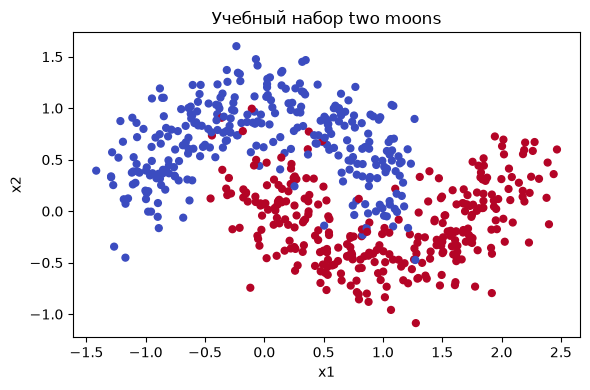

In [22]:
# Листинг 5 — Импорты моделей, метрик и загрузка example_moons.csv
# Импортируем компоненты scikit-learn, используемые далее в примере.
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
 
# Загружаем локальную копию: выполнение не зависит от доступа к сети.
DATA_DIR = Path("ML_Lab3_Datasets")
frame = pd.read_csv(DATA_DIR / "example_moons.csv")
X = frame[["x1", "x2"]].to_numpy(dtype=float)
y = frame["target"].to_numpy()
 
# Проверяем размер, пропуски и распределение целевых классов.
print("Размер:", frame.shape)
print("Пропуски:", int(frame.isna().sum().sum()))
print("Классы:\n", frame["target"].value_counts().sort_index())
 
# Визуализация допустима до разбиения: она не обучает модель.
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=24)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Учебный набор two moons")
plt.tight_layout()
plt.show()


два "полумесяца", с вкраплениями некоторых объектов в другие
прямую здесь не провести, линейная классивикация здесь невохможна, однако решить помогут нелинейные модели, SVM и KNN

In [23]:
# Листинг 6 — Фиксация train, validation, test и baseline
# Сначала откладываем закрытый test: он не участвует в выборе моделей.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)
 
# Из оставшихся 80 % выделяем validation: итоговая пропорция 60/20/20.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    stratify=y_train_full,
    random_state=SEED,
)
 
# Baseline всегда предсказывает самый частый класс обучающей выборки.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_val)
 
# Macro-F1 показывает, насколько модель превосходит тривиальное правило.
baseline_f1 = f1_score(y_val, baseline_prediction, average="macro")
print("Размеры:", len(X_train), len(X_val), len(X_test))
print("Baseline validation macro-F1:", round(baseline_f1, 4))


Размеры: 360 120 120
Baseline validation macro-F1: 0.3333


In [24]:
# Листинг 7 — kNN-классификатор средствами NumPy
def manual_knn_predict(
    X_train,
    y_train,
    X_query,
    *,
    k=5,
    weighted=False,
):
    """Предсказывает класс каждого объекта из X_query."""
    # Явно преобразуем входы в массивы и проверяем допустимость k.
    X_train = np.asarray(X_train, dtype=float)
    X_query = np.asarray(X_query, dtype=float)
    y_train = np.asarray(y_train)
    if not 1 <= k <= len(X_train):
        raise ValueError("k должно лежать между 1 и размером train")
 
    predictions = []
    for query in X_query:
        # Евклидово расстояние вычисляется до каждого объекта train.
        distances = np.sqrt(np.sum((X_train - query) ** 2, axis=1))
        order = np.argsort(distances, kind="mergesort")[:k]
        neighbor_labels = y_train[order]
        neighbor_distances = distances[order]
 
        # При точном совпадении голосуют только соседи с нулевой дистанцией.
        if weighted and np.any(neighbor_distances <= 1e-12):
            weights = (neighbor_distances <= 1e-12).astype(float)
        # В остальных случаях взвешенный режим усиливает близких соседей.
        elif weighted:
            weights = 1.0 / neighbor_distances
        else:
            weights = np.ones(k, dtype=float)
 
        # Суммируем голоса отдельно для каждого встреченного класса.
        scores = {}
        for label, weight in zip(neighbor_labels, weights):
            scores[label] = scores.get(label, 0.0) + float(weight)
 
        # При равенстве голосов выбираем минимальную метку, как sklearn.
        predictions.append(max(sorted(scores), key=scores.get))
    return np.asarray(predictions)


In [25]:
# Листинг 8 — Сопоставление ручного kNN с KNeighborsClassifier
# Масштабировщик обучается только по X_train.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
 
# Получаем прогноз ручной реализации на validation.
manual_prediction = manual_knn_predict(
    X_train_scaled,
    y_train,
    X_val_scaled,
    k=7,
    weighted=True,
)
 
# Готовая модель получает те же данные и те же параметры.
library_knn = KNeighborsClassifier(
    n_neighbors=7,
    weights="distance",
    p=2,
)
library_knn.fit(X_train_scaled, y_train)
library_prediction = library_knn.predict(X_val_scaled)
 
# Совпадение прогнозов подтверждает корректность базовой реализации.
agreement = np.mean(manual_prediction == library_prediction)
manual_f1 = f1_score(y_val, manual_prediction, average="macro")
print("Доля совпавших прогнозов:", round(agreement, 4))
print("Ручной kNN macro-F1:", round(manual_f1, 4))


Доля совпавших прогнозов: 1.0
Ручной kNN macro-F1: 0.95


In [26]:
# Листинг 9 — Эксперимент с искусственно искажённым масштабом
# Умножаем второй признак на 100, не изменяя информацию в данных.
X_train_distorted = X_train.copy()
X_val_distorted = X_val.copy()
X_train_distorted[:, 1] *= 100.0
X_val_distorted[:, 1] *= 100.0
 
# Модель без стандартизации почти игнорирует первый признак.
knn_without_scaling = KNeighborsClassifier(
    n_neighbors=11,
    weights="distance",
)
knn_without_scaling.fit(X_train_distorted, y_train)
pred_without = knn_without_scaling.predict(X_val_distorted)
 
# Pipeline обучает StandardScaler только на train, затем применяет kNN.
knn_with_scaling = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=11,
        weights="distance",
    )),
])
knn_with_scaling.fit(X_train_distorted, y_train)
pred_with = knn_with_scaling.predict(X_val_distorted)
 
# Сравниваем модели одной метрикой и на одном validation.
print("Без scaling:", f1_score(y_val, pred_without, average="macro"))
print("Со scaling:", f1_score(y_val, pred_with, average="macro"))



Без scaling: 0.883300916921367
Со scaling: 0.9583304396138621


In [27]:
# Листинг 10 — Таблица метрик классификации
def classification_metrics(y_true, y_pred):
    """Возвращает три взаимодополняющие метрики классификации."""
    # Accuracy удобна для общего понимания доли правильных ответов.
    accuracy = accuracy_score(y_true, y_pred)
 
    # Balanced accuracy одинаково учитывает полноту каждого класса.
    balanced = balanced_accuracy_score(y_true, y_pred)
 
    # Macro-F1 одинаково взвешивает классы и служит основным критерием.
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    return {
        "accuracy": accuracy,
        "balanced_accuracy": balanced,
        "macro_f1": macro_f1,
    }
 
# Проверяем формат результата на константном baseline.
print(classification_metrics(y_val, baseline_prediction))


{'accuracy': 0.5, 'balanced_accuracy': 0.5, 'macro_f1': 0.3333333333333333}


In [28]:
# Листинг 11 — Кросс-валидация k, weights и p
# Одинаковые фолды используются для всех конфигураций.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)
 
# StandardScaler находится внутри Pipeline и переобучается на каждом фолде.
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier()),
])
 
# Сетка проверяет размер окрестности, голоса и две метрики Минковского.
knn_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}
knn_search = GridSearchCV(
    knn_pipeline,
    knn_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
knn_search.fit(X_train, y_train)
 
# Best score относится к CV на train, а не к validation или test.
print("Лучшие параметры:", knn_search.best_params_)
print("Средний CV macro-F1:", round(knn_search.best_score_, 4))
knn_val_prediction = knn_search.predict(X_val)
print(classification_metrics(y_val, knn_val_prediction))


Лучшие параметры: {'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'distance'}
Средний CV macro-F1: 0.9583
{'accuracy': 0.9583333333333334, 'balanced_accuracy': 0.9583333333333333, 'macro_f1': 0.9583304396138621}


Для отчёта постройте график среднего CV macro-F1 в зависимости от k. Отдельными линиями покажите uniform/distance и p = 1/2 либо приведите сводную таблицу лучших комбинаций.

In [29]:
# Листинг 12 — Два семейства SVM по одинаковым фолдам
# Линейный SVM настраивается только по параметру C.
linear_svm = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="linear")),
])
linear_search = GridSearchCV(
    linear_svm,
    {"model__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
linear_search.fit(X_train, y_train)
 
# Для RBF-SVM параметры C и gamma подбираются совместно.
rbf_svm = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="rbf")),
])
rbf_search = GridSearchCV(
    rbf_svm,
    {
        "model__C": [0.1, 1.0, 10.0, 100.0],
        "model__gamma": ["scale", 0.01, 0.1, 1.0, 10.0],
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
rbf_search.fit(X_train, y_train)
 
# Validation остаётся независимым от внутренней кросс-валидации.
for name, search in {
    "linear SVM": linear_search,
    "RBF SVM": rbf_search,
}.items():
    prediction = search.predict(X_val)
    print(name, search.best_params_)
    print(classification_metrics(y_val, prediction))


linear SVM {'model__C': 1.0}
{'accuracy': 0.85, 'balanced_accuracy': 0.85, 'macro_f1': 0.8498331479421579}
RBF SVM {'model__C': 10.0, 'model__gamma': 1.0}
{'accuracy': 0.9666666666666667, 'balanced_accuracy': 0.9666666666666667, 'macro_f1': 0.9666666666666667}


In [30]:
# Листинг 13 — Измерение fit, predict и размера опорного множества
def measure_classifier(name, estimator, X_train, y_train, X_val, y_val):
    """Переобучает модель и измеряет качество и время."""
    # clone создаёт чистую модель с теми же выбранными параметрами.
    model = clone(estimator)
    start = perf_counter()
    model.fit(X_train, y_train)
    fit_ms = 1000.0 * (perf_counter() - start)
 
    # Время приводим к 1000 объектам для удобства сравнения.
    start = perf_counter()
    prediction = model.predict(X_val)
    predict_seconds = perf_counter() - start
    predict_ms_1000 = 1_000_000.0 * predict_seconds / len(X_val)
 
    # Для SVC считаем опорные векторы, для kNN — сохранённый train.
    inner_model = model.named_steps["model"]
    if hasattr(inner_model, "n_support_"):
        stored_objects = int(inner_model.n_support_.sum())
    else:
        stored_objects = len(X_train)
 
    metrics = classification_metrics(y_val, prediction)
    return {
        "model": name,
        **metrics,
        "fit_ms": fit_ms,
        "predict_ms_per_1000": predict_ms_1000,
        "stored_objects": stored_objects,
        "stored_share": stored_objects / len(X_train),
    }
 
# Все семейства оцениваются на одном и том же validation.
candidates = {
    "kNN": knn_search.best_estimator_,
    "linear SVM": linear_search.best_estimator_,
    "RBF SVM": rbf_search.best_estimator_,
}
comparison = pd.DataFrame([
    measure_classifier(name, model, X_train, y_train, X_val, y_val)
    for name, model in candidates.items()
]).sort_values("macro_f1", ascending=False)
print(comparison.round(4))


        model  accuracy  balanced_accuracy  macro_f1  fit_ms  \
2     RBF SVM    0.9667             0.9667    0.9667  2.4078   
0         kNN    0.9583             0.9583    0.9583  2.1373   
1  linear SVM    0.8500             0.8500    0.8498  2.4798   

   predict_ms_per_1000  stored_objects  stored_share  
2               5.1283              58        0.1611  
0               8.8225             360        1.0000  
1               3.7425             122        0.3389  


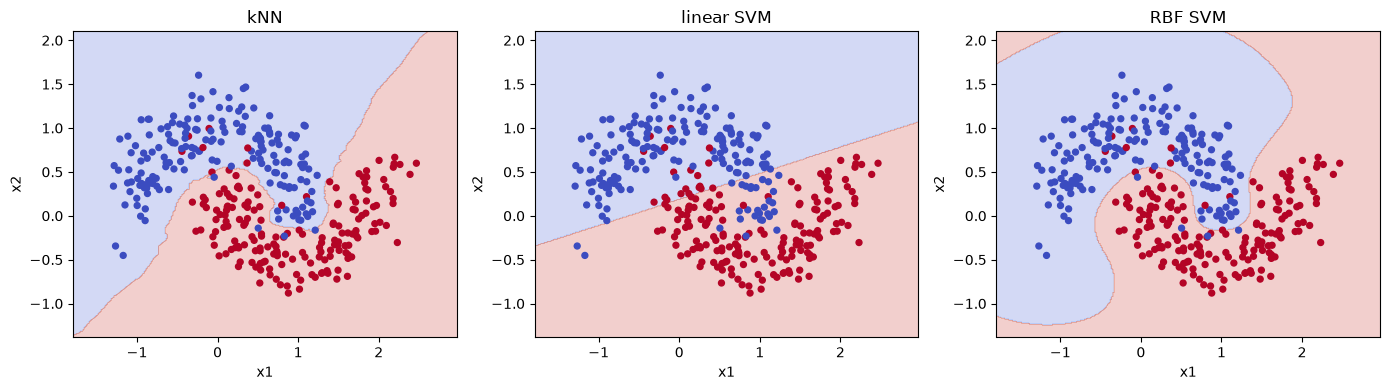

In [31]:
# Листинг 14 — Решающие области kNN, linear SVM и RBF SVM
def plot_decision_region(ax, estimator, X, y, title):
    """Обучает модель и отображает её решение на двумерной сетке."""
    # Сетку строим в исходном пространстве; scaling выполняет Pipeline.
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x1_min, x1_max, 300),
        np.linspace(x2_min, x2_max, 300),
    )
 
    # Для честной демонстрации модель обучается только на train.
    model = clone(estimator)
    model.fit(X, y)
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
 
    # Фон показывает классы модели, точки — реальные train-объекты.
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=18)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
 
# Test не используется даже для иллюстрации границы.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, estimator) in zip(axes, candidates.items()):
    plot_decision_region(ax, estimator, X_train, y_train, name)
plt.tight_layout()
plt.show()


In [32]:
# Листинг 15 — Выбор по validation, переобучение и однократный test
# Сравниваем уже настроенные семейства только по validation macro-F1.
validation_scores = {}
for name, estimator in candidates.items():
    prediction = estimator.predict(X_val)
    validation_scores[name] = f1_score(
        y_val,
        prediction,
        average="macro",
    )
 
# После этой строки семейство и все гиперпараметры считаются зафиксированными.
best_name = max(validation_scores, key=validation_scores.get)
best_pipeline = candidates[best_name]
print("Выбрана модель:", best_name)
print("Validation scores:", validation_scores)
 
# Объединяем train и validation только после завершения выбора.
X_train_val = np.vstack([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])
final_model = clone(best_pipeline)
final_model.fit(X_train_val, y_train_val)
 
# Test открывается ровно один раз для итоговой несмещённой оценки.
test_prediction = final_model.predict(X_test)
test_metrics = classification_metrics(y_test, test_prediction)
print("Test metrics:", test_metrics)
print(classification_report(y_test, test_prediction, digits=3))


Выбрана модель: RBF SVM
Validation scores: {'kNN': 0.9583304396138621, 'linear SVM': 0.8498331479421579, 'RBF SVM': 0.9666666666666667}
Test metrics: {'accuracy': 0.9333333333333333, 'balanced_accuracy': 0.9333333333333333, 'macro_f1': 0.9333333333333333}
              precision    recall  f1-score   support

           0      0.933     0.933     0.933        60
           1      0.933     0.933     0.933        60

    accuracy                          0.933       120
   macro avg      0.933     0.933     0.933       120
weighted avg      0.933     0.933     0.933       120



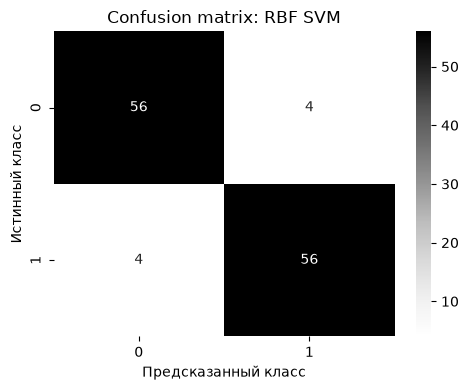

Число ошибок: 8
           x1        x2  true  predicted
7    1.310327  0.332422     1          0
33   0.857569 -0.161625     0          1
49   1.301111 -0.013379     1          0
68  -0.354182  0.401203     1          0
76   1.273632 -0.474188     0          1
78   0.885350 -0.110789     1          0
83   1.085940 -0.148548     0          1
113  0.862380 -0.168271     0          1


In [33]:
# Листинг 16 — Матрица ошибок и таблица ошибочных объектов
# Фиксированный порядок классов делает подписи матрицы однозначными.
labels = np.unique(y_test)
matrix = confusion_matrix(y_test, test_prediction, labels=labels)
plt.figure(figsize=(5, 4))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Greys",
    xticklabels=labels,
    yticklabels=labels,
)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.show()
 
# Формируем таблицу только для объектов, на которых модель ошиблась.
errors = pd.DataFrame({
    "x1": X_test[:, 0],
    "x2": X_test[:, 1],
    "true": y_test,
    "predicted": test_prediction,
})
errors = errors.loc[errors["true"] != errors["predicted"]]
print("Число ошибок:", len(errors))
print(errors.head(10))
